# E95 · Election night: updating a frozen forecast as the races are called

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: E94's data and its corrected frozen forecast of the 2026 US midterms (see E94 for sources and licences), and the race calls made on election night, 3 November 2026, by the AP and the networks, entered by hand from their live pages (one small CSV that grows through the night) |
| **You will learn** | A **race call as data**: an interval on the true margin, with the race's own noise integrated out · **importance reweighting** of a frozen posterior by the likelihood of new data, with the **effective sample size** as the warning light · the same update as a **PyMC refit** with a `Potential`, and when the two agree · why an expected call says almost nothing and a **margin** says a lot · reading **"too close to call"** as data · **conditional forecasts**: what each race still out would do to control of the House and the Senate |

## The setting

E94 froze a forecast of the 2026 midterms on the afternoon of election day: 237 Democratic House seats
with a 0.94 chance of a majority, and 52 Democratic-caucus Senate seats with a 0.78 chance of control.
Then the polls closed. At 7 pm Eastern the first states stopped voting, and within minutes the AP and
the networks called Georgia's Senate race for the Democrat, Jon Ossoff. Virginia, New Hampshire,
Massachusetts and Rhode Island followed. Florida, where the forecast had the Republican, Ashley Moody,
ahead by five points, was "too close to call".

The natural question is the one a viewer asks: does Georgia change the prediction? The races are not
independent. Every race in the forecast shares one national environment and one polling error, and
the races in one state share a state effect, so a result in Georgia is evidence about Ohio and Iowa.
How much evidence depends on how surprising it is. This is Bayes' rule applied to a forecast that
already exists: the frozen posterior is the prior, and each call is a new observation. Election-night
models do this (the *New York Times* "needle" updates from precinct returns; Cohn 2016), and it is the
same idea as nowcasting from partial data in E38 and E90.

Two things make it a lesson rather than a lookup. A **call** is not a margin: it tells us only that the
winner is ahead by enough for the AP to be sure. That is an interval on the margin, and the likelihood
of an interval needs care. And there are two ways to update. **Importance reweighting** keeps the frozen
draws and weights each by the likelihood of the night's results; it is instant and exact, but it fails
when the results are surprising. A **refit** adds the results to the model and samples again; it costs
half a minute and always works. We do both and see when they agree.

This notebook is rebuilt during the night as calls come in. Every number about the night (tables,
figures and the bulletin in section 6) is computed from the calls file; the prose describes the method
and the frozen eve, which do not change. The snapshot time is in the calls table.

| part | question | tool |
|---|---|---|
| 1 | Can we rebuild the frozen eve exactly? | E94's own model code and seed |
| 2 | What has been called? | a hand-entered CSV of calls, with each call's surprise |
| 3 | Does Georgia change the prediction? | a call as an interval; importance weights and their ESS; a refit with a `Potential` |
| 4 | What would Ossoff's margin say? | a margin as data; refits across possible margins |
| 5 | What is still out, and what does each race decide? | conditional control probabilities; a map |
| 6 | Where the night stands | a bulletin computed from the latest calls |

In [1]:
import contextlib
import io
import json
import logging
import os
import sys
import time
import warnings

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "1")  # before NumPy: one BLAS thread per chain
os.environ.setdefault("JAX_PLATFORMS", "cpu")  # nothing here uses a GPU

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from IPython.display import Markdown, display
from matplotlib.collections import LineCollection, PolyCollection
from scipy.stats import gaussian_kde, norm

from pymc_challenges import data

sys.modules.pop("jax", None)   # ArviZ's lazy JAX stub would import all of JAX for nothing (see E89 and E94)

RANDOM_SEED = 95
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, message=".*tight.*")
warnings.filterwarnings("ignore", message=".*sample_stats.*")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
T_START = time.time()
D_C, R_C, INK, MUTED, LIGHT, GOLD = "#2166ac", "#c0392b", "#222222", "#8a8a8a", "#d9d9d9", "#e08e0b"
TIMES = {}

## 1 · The eve, rebuilt

The update needs the frozen posterior itself, not just its summaries: every draw of the national
margin, the polling error, the state effects and each race's mean. E94 froze only summaries, so we
rebuild the posterior with E94's own code. The cell below runs E94's sections 1 to 3.2 (the data, the
midterm prior and the model functions) from its source file, quietly, and then calls E94's
`fit_cycle(2026)` with E94's seed. The data files are the ones whose hashes the frozen file records, so
this is the same posterior, sampled the same way.

In [2]:
E94_SRC = data.DATA_DIR.parent / "notebook_src/examples/E94_midterms_polls_money.py"


def load_e94():
    """Run E94's sections 1 to 3.2 (data, prior, model code), quietly, and return its namespace."""
    src = E94_SRC.read_text()
    cut = src.index("# ### 3.3 Failure 1")
    ns = {"__name__": "e94"}
    with contextlib.redirect_stdout(io.StringIO()):
        exec(compile(src[: src.rindex("# %%", 0, cut)], str(E94_SRC), "exec"), ns)
    plt.close("all")
    return ns


E94 = load_e94()
prepare, build_model, simulate, seats, fit_cycle = (E94[k] for k in ("prepare", "build_model", "simulate", "seats",
                                                                     "fit_cycle"))
t0 = time.time()
eve = fit_cycle(2026, keep=True)           # E94's own call, with E94's seed: the same draws as its section 7
TIMES["eve fit"] = time.time() - t0
d = eve["d"]
tm, tgt = d["tm"], d["tgt"]
FROZEN = json.load(open(data.path("e94_freeze_2026_v2")))
fz = pd.DataFrame(FROZEN["races"]).set_index("race")
for fname, h in FROZEN["inputs_sha256_content"].items():
    p = data.DATA_DIR / fname
    import gzip
    import hashlib
    b = p.read_bytes()
    same = hashlib.sha256(gzip.decompress(b) if fname.endswith(".gz") else b).hexdigest() == h
    print(f"input {fname:20s} {'as frozen' if same else 'CHANGED since the freeze'}")
notup = {k: int(v) for k, v in E94["build_log"]["senate_2026_not_up"].items()}
NOT_UP = notup["Democratic"] + notup["Independent"]
s_ = eve["seats"]
gap = np.abs((eve["sim"] > 0).mean(0) - fz.loc[tm.race, "pD"].to_numpy())
print({k: eve[k] for k in ("divergences", "max r_hat", "min ESS")})
print(f"P(D) against the frozen v2 file: mean difference {gap.mean():.3f}, largest {gap.max():.2f}")
print(f"House D seats {np.median(s_['H']):.0f}, P(majority) {(s_['H'] >= 218).mean():.2f} (frozen "
      f"{FROZEN['seats']['H']['P_D_control']:.2f}); Senate D caucus {np.median(s_['S'] + NOT_UP):.0f}, "
      f"P(control) {(s_['S'] + NOT_UP >= 51).mean():.2f} (frozen {FROZEN['seats']['S']['P_D_control']:.2f})")

input e94_races.csv        as frozen
input e94_polls.csv        as frozen
input e94_reports.csv.gz   as frozen
input e94_ie.csv.gz        as frozen
input e94_pollerr.csv      as frozen
{'divergences': 0, 'max r_hat': 1.011, 'min ESS': 347}
P(D) against the frozen v2 file: mean difference 0.002, largest 0.04
House D seats 237, P(majority) 0.94 (frozen 0.94); Senate D caucus 52, P(control) 0.79 (frozen 0.78)


The inputs are unchanged, the sampler is clean, and the rebuilt forecast matches the frozen file: race
chances differ by 0.002 on average and at most 0.04 (the frozen file came from a separate run of the
same code), and the control probabilities agree to the second decimal.

For the update we need each draw's **mean** margin in every race, before the race's own noise. In
E94's model a race with polls has its margin $m_r$ as a parameter, so the sampler already holds it. A
race without polls has margin

$$m_r = \mu_r(\theta) + \sigma_{o(r)}\,\varepsilon_r, \qquad \varepsilon_r \sim \mathrm{Normal}(0, 1),$$

where $\mu_r(\theta)$ collects the national margin, the office intercept, the fundamentals and the
state effect, and $\sigma_{o(r)}$ is the race-level sd of its office. E94's `simulate` adds the noise
by drawing $\varepsilon_r$; here we keep $\mu_r$ and $\sigma_{o(r)}$ separately for all 4,000 draws, so
that the noise can be integrated out exactly.

In [3]:
def eve_draws(d, idata):
    """Every posterior draw's mean margin and race-level sd for each modelled race (no race noise added).

    For a polled race the sampler already holds its margin (m_pol, noise included), so its sd is 0."""
    tm = d["tm"]
    post = az.extract(idata)
    n = post.sizes["sample"]
    isS = (tm.office == "S").to_numpy().astype(int)
    X = np.broadcast_to(np.c_[tm.leanx, tm.inc, np.nan_to_num(tm.money.to_numpy())], (n, len(tm), 3)).copy()
    st = tm.state.map({s: i for i, s in enumerate(d["states"])}).to_numpy()
    T = lambda v, *dims: post[v].transpose("sample", *dims).values  # noqa: E731
    if len(d["miss"]):
        X[:, d["miss"], 2] = T("money_missing", "missing_race")
    icpt = post["N"].values[:, None] + T("gamma", "office") + post["s_int"].values[:, None] * T("z_int_t", "office")
    mu = (icpt[:, isS] + (T("beta", "office", "x")[:, isS, :] * X).sum(-1)
          + (T("z_st_t", "state") * post["s_state"].values[:, None])[:, st])
    sd = np.broadcast_to(T("sig", "office")[:, isS], mu.shape).copy()
    pol_i = np.array([tm.index[tm.race == r][0] for r in d["polled"]])
    mu[:, pol_i], sd[:, pol_i] = T("m_pol", "polled"), 0.0
    return {"mu": mu, "sd": sd, "N": post["N"].values, "bias": post["bias"].values}


E = eve_draws(d, eve["idata"])
RACE = {r: i for i, r in enumerate(tm.race)}
U = np.random.default_rng(RANDOM_SEED).random(E["mu"].shape)     # common random numbers for every outcome draw
p_eve = norm.cdf(E["mu"] / np.where(E["sd"] > 0, E["sd"], 1e-9)).mean(0)
print(f"{E['mu'].shape[0]} draws x {E['mu'].shape[1]} races ({len(d['polled'])} with polls); P(D) from the means "
      f"against the frozen file: largest difference {np.abs(p_eve - fz.loc[tm.race, 'pD']).max():.3f}")

4000 draws x 451 races (104 with polls); P(D) from the means against the frozen file: largest difference 0.040


## 2 · The night so far

The calls come from the outlets' live pages, entered by hand with the outlet that made each call and
the time of the snapshot. A call is a projection, not a count: the AP declares a winner when its
analysts are sure who leads, often with most of the vote uncounted, and their models know which ballots
are still out. A partial count is a different thing. Ballots are counted in batches whose order depends
on the state's rules, and the batches lean differently, because the voters who vote early, by mail and
on the day are not the same people. In Georgia, Florida and North Carolina the early and mail ballots,
which lean Democratic, are counted and reported first, so the early count runs blue and drifts red as
election-day precincts come in; the 64-36 Ossoff led by with 56% of the expected vote overstates his
final margin by an amount nobody knows on the night. In Pennsylvania and Wisconsin mail ballots may not
be processed before election day and often come last, so the drift runs the other way; in Arizona,
Nevada and California, late-arriving mail and provisional ballots are counted for days. The same share
counted means different things in different states.

So we keep partial counts but use a margin only once a race is at least 95% counted, and even then the
ballots still out may differ from those counted. If the outstanding share $u$ could lean up to $k = 30$
points differently from the counted ballots, the final margin could differ from the count by about
$k\,u$, so a near-final margin enters with sd $\sqrt{0.5^2 + (k u)^2}$: 1.5 points at 95% counted, 0.5
when the count is complete. "Too close to call" is information too, and section 3.2 treats it as such.

The **surprise** of a result is $-\log P(\text{result})$ under the frozen forecast, in nats. It is the
amount of information the result carries, and it bounds how far the result can move anything else.

In [4]:
data.describe("e95_calls_2026")
calls = data.load("e95_calls_2026")
calls = calls.join(fz[["pD", "pred", "q10", "q90"]], on="race")
calls["surprise"] = -np.log(np.clip(np.where(calls.winner == "D", calls.pD, 1 - calls.pD), 1e-4, 1))
calls["surprise"] = calls.surprise.where(calls.status == "called")
AS_OF = calls.as_of_et.max()
print(f"snapshot: {AS_OF} ET; {int((calls.status == 'called').sum())} races called, "
      f"{int((calls.status == 'too close').sum())} too close to call")
print(calls[["race", "status", "winner", "reported_by", "pD", "pred", "q10", "q90", "surprise"]]
      .round(3).to_string(index=False))

e95_calls_2026: race (as in e94_races), status (called or too close), winner (D or R), reported_by, as_of_et, the partial count where one was given (d_pct, r_pct, pct_expected_in), source_url.
  source: Election-night race calls (projections by the AP and the networks, not certified results) for the 2026 US midterms, entered by hand from the outlets' live pages named in each row; a snapshot that grows through the night.
  url:    https://abcnews.com/Politics/live-updates/midterm-elections-live-updates/?id=137782085
snapshot: 2026-11-03 20:50 ET; 9 races called, 0 too close to call
 race status winner                         reported_by    pD   pred     q10    q90  surprise
 GA-S called      D AP, ABC, CBS, NBC, Decision Desk HQ 0.994 14.101   7.378 20.895     0.007
 VA-S called      D                                 CBS 0.998 20.701  11.452 29.619     0.002
 NH-S called      D                            NBC, Fox 0.974 10.292   3.463 16.851     0.026
 MA-S called      D                 

Georgia's call was expected. The frozen forecast gave Ossoff a 0.994 chance and a median margin of
D+14, so his win carries 0.007 nats of information, about a hundredth of a coin toss. The other early
calls are like it: Democratic holds in states the forecast already gave them. The surprises of the
night so far, if there are any, are in the column on the right.

## 3 · A call is an interval

What does "the AP called Georgia for Ossoff" tell us about the model? It says the true margin is
positive. We soften the edge a little, because the AP is occasionally wrong and because a margin of
exactly zero is not special: the likelihood of a call for the Democrat is

$$P(\text{call D} \mid \theta) = P(m_r > 0 \mid \theta) = \Phi\!\left(\frac{\mu_r(\theta)}{\sqrt{\sigma_{o(r)}^2 + \tau^2}}\right),$$

with $\tau = 0.5$ points. For a race without polls the race noise is integrated out, which is why
$\sigma_{o(r)}$ appears; for a race with polls $m_r$ is a parameter and only $\tau$ remains. A call for
the Republican uses $\Phi(-\mu_r/\cdot)$, and "too close" uses the interval $-c < m_r < c$.

**Importance reweighting.** The frozen posterior $p(\theta \mid \text{polls})$ becomes
$p(\theta \mid \text{polls}, \text{calls}) \propto p(\theta \mid \text{polls})\, P(\text{calls} \mid \theta)$,
so the frozen draws stay valid if each is weighted by $w_s \propto \prod_r P(\text{call}_r \mid \theta_s)$.
This is exact for the same reason as E94's prior reweighting: only a factor of the posterior changes.
What can go wrong is the sample, not the algebra. If a few draws carry all the weight, the weighted
average rests on those few. The effective sample size $\mathrm{ESS} = 1/\sum_s w_s^2$ (weights summing
to one) counts how many equally weighted draws the weighted sample is worth.

Forecasts after a call also need each race's chance given the draw and the call: 1 or 0 for a called
race, the truncated normal's share above zero for a race known to be close, and
$\Phi(\mu_r/\sigma_{o(r)})$ otherwise. Seat totals come from one simulated election per draw, using the
same uniform random numbers in every scenario so that differences between scenarios are not noise.

In [5]:
TAU = 0.5     # points: how far on the wrong side of zero a called race could still be (a soft edge)
CLOSE = 3.0   # points: "too close to call" read as |margin| < CLOSE (an assumption, varied in section 3.2)
FINAL = 95    # a race counts as counted once this share of the expected vote is in; its margin is then data
SKEW = 30.0   # points: how differently the ballots still out could lean from those counted (any direction)


def tau_m(pct_in):
    """sd of a counted margin around the final one: counting noise plus the skew of the uncounted share."""
    return float(np.hypot(0.5, SKEW * (1 - pct_in / 100)))


def info_from(calls, close=CLOSE):
    """One row per race with information: the interval (lo, hi) its true margin lies in."""
    rows = []
    for r in calls.itertuples():
        if r.status == "called":
            rows.append((r.race, 0.0, np.inf) if r.winner == "D" else (r.race, -np.inf, 0.0))
        elif r.status == "too close":
            rows.append((r.race, -close, close))
    return rows


def margins_from(calls):
    """(race, two-party margin) for the races counted to at least FINAL percent."""
    ok = calls[(calls.pct_expected_in >= FINAL) & calls.d_pct.notna() & calls.r_pct.notna()]
    return [(r.race, 100 * (r.d_pct - r.r_pct) / (r.d_pct + r.r_pct), tau_m(r.pct_expected_in))
            for r in ok.itertuples()]


def loglik(mu, sd, lo, hi):
    """log P(lo < margin < hi) for margin ~ Normal(mu, sqrt(sd^2 + TAU^2)), per draw."""
    s = np.sqrt(sd**2 + TAU**2)
    if np.isinf(hi):
        return norm.logcdf((mu - lo) / s)
    if np.isinf(lo):
        return norm.logcdf((hi - mu) / s)
    return np.log(np.clip(norm.cdf((hi - mu) / s) - norm.cdf((lo - mu) / s), 1e-300, None))


def weights(E, info):
    lw = np.zeros(E["mu"].shape[0])
    for race, lo, hi in info:
        i = RACE[race]
        lw += loglik(E["mu"][:, i], E["sd"][:, i], lo, hi)
    w = np.exp(lw - lw.max())
    return w / w.sum()


def ess(w):
    return 1.0 / np.sum(w**2)


def outcome_probs(E, info):
    """P(D wins the race | draw, information): 1 or 0 for a called race, truncated for a close one."""
    p = norm.cdf(E["mu"] / np.where(E["sd"] > 0, E["sd"], 1e-9))
    for race, lo, hi in info:
        i = RACE[race]
        s = np.sqrt(E["sd"][:, i] ** 2 + TAU**2)
        a, b = norm.cdf((lo - E["mu"][:, i]) / s), norm.cdf((hi - E["mu"][:, i]) / s)
        z = norm.cdf(-E["mu"][:, i] / s)
        p[:, i] = np.clip((b - np.clip(z, a, b)) / np.clip(b - a, 1e-300, None), 0, 1)
    return p


def summarise(E, info, w=None):
    """Weighted forecast: per-race P(D), one simulated election per draw, and control of each chamber."""
    w = np.full(E["mu"].shape[0], 1 / E["mu"].shape[0]) if w is None else w
    p = outcome_probs(E, info)
    won = U < p
    st = seats(d, np.where(won, 1.0, -1.0))
    sen = st["S"] + NOT_UP
    return {"w": w, "ess": ess(w), "pD": w @ p, "won": won, "H": st["H"], "S": sen,
            "P(House)": float(w @ (st["H"] >= 218)), "P(Senate)": float(w @ (sen >= 51)),
            "N": E["N"], "bias": E["bias"], "mu": E["mu"]}


def wq(x, w, qs=(0.05, 0.5, 0.95)):
    o = np.argsort(x)
    c = np.cumsum(w[o])
    return np.interp(qs, c - w[o] / 2, x[o])


def line(lab, S):
    iv = lambda v, f: "{1:{f}} [{0:{f}}, {2:{f}}]".format(*wq(v, S["w"]), f=f)  # noqa: E731
    return {"": lab, "ESS": round(S["ess"]), "P(D House)": round(S["P(House)"], 3),
            "P(D Senate)": round(S["P(Senate)"], 3), "House seats": iv(S["H"], ".0f"),
            "Senate seats": iv(S["S"], ".0f"), "N": iv(S["N"], "+.1f"), "polling error": iv(S["bias"], "+.1f")}


EVE = summarise(E, [])
GA = [("GA-S", 0.0, np.inf)]
S_GA = summarise(E, GA, weights(E, GA))
GA_R = [("GA-S", -np.inf, 0.0)]
S_GAR = summarise(E, GA_R, weights(E, GA_R))
print(pd.DataFrame([line("eve (frozen posterior)", EVE), line("Georgia called for Ossoff", S_GA),
                    line("if Georgia had gone to Collins", S_GAR)]).set_index("").to_string())
sen_rows = tm.index[tm.office == "S"]
dp = pd.DataFrame({"race": tm.race[sen_rows], "eve": EVE["pD"][sen_rows], "GA called D": S_GA["pD"][sen_rows],
                   "GA to R": S_GAR["pD"][sen_rows]})
print(f"largest move in another Senate race's P(D) from the Ossoff call: "
      f"{(dp['GA called D'] - dp.eve)[dp.race != 'GA-S'].abs().max():.4f}")

                                 ESS  P(D House)  P(D Senate)     House seats Senate seats                   N       polling error
                                                                                                                                  
eve (frozen posterior)          4000       0.946        0.801  237 [217, 262]  52 [48, 56]  +8.0 [+3.2, +12.8]   +1.0 [-3.7, +5.9]
Georgia called for Ossoff       3987       0.948        0.804  237 [217, 262]  52 [49, 56]  +8.0 [+3.2, +12.8]   +1.0 [-3.7, +5.8]
if Georgia had gone to Collins    16       0.422        0.139  215 [201, 243]  47 [44, 52]  +2.2 [-0.9, +10.1]  +7.3 [-0.5, +11.0]
largest move in another Senate race's P(D) from the Ossoff call: 0.0016


So: **no, Georgia does not change the prediction.** After the call the chance of a Democratic House is
0.948 instead of 0.946 and of a Democratic Senate 0.804 instead of 0.801; no other Senate race moves by
more than 0.004. The weights barely vary (ESS 3,987 of 4,000), because only the 26 draws in which
Ossoff loses are down-weighted.

The last row asks the opposite question: what if Collins had won? That result had a 0.0065 chance, and
it would have said a great deal. The polling error would jump from +1.0 to about +7 points (the polls
far too Democratic), and both chambers would tilt Republican. But the ESS is 16: the whole answer rests
on the handful of draws in which Ossoff lost, so the numbers in that row are rough. That is the
warning light working. A surprising result is exactly the one reweighting cannot handle, and section
3.1 refits instead.

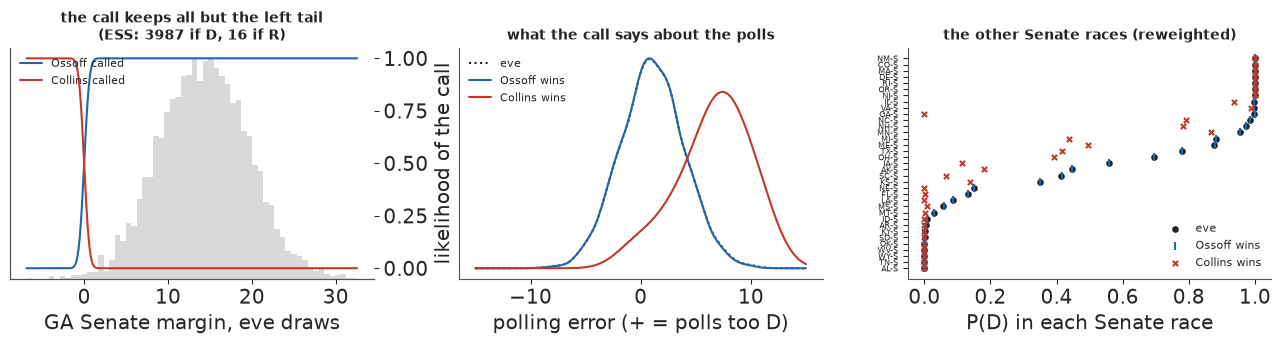

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
ax = axes[0]
g_i = RACE["GA-S"]
ax.hist(E["mu"][:, g_i], bins=60, color=LIGHT, density=True)
ax.set_xlabel("GA Senate margin, eve draws")
ax.set_yticks([])
ax2 = ax.twinx()
gm = np.linspace(E["mu"][:, g_i].min(), E["mu"][:, g_i].max(), 300)
ax2.plot(gm, norm.cdf(gm / TAU), color=D_C, label="Ossoff called")
ax2.plot(gm, norm.cdf(-gm / TAU), color=R_C, label="Collins called")
ax2.set_ylabel("likelihood of the call")
ax2.legend(fontsize=8, loc="upper left")
ax.set_title(f"the call keeps all but the left tail\n(ESS: {S_GA['ess']:.0f} if D, {S_GAR['ess']:.0f} if R)",
             fontsize=10)
ax = axes[1]
gx = np.linspace(-15, 15, 200)
for lab, S, c, ls in (("eve", EVE, INK, ":"), ("Ossoff wins", S_GA, D_C, "-"), ("Collins wins", S_GAR, R_C, "-")):
    ax.plot(gx, gaussian_kde(S["bias"], weights=S["w"])(gx), color=c, ls=ls, label=lab)
ax.set_xlabel("polling error (+ = polls too D)")
ax.set_yticks([])
ax.legend(fontsize=8)
ax.set_title("what the call says about the polls", fontsize=10)
ax = axes[2]
o = np.argsort(dp.eve.to_numpy())
ax.scatter(dp.eve.to_numpy()[o], np.arange(len(o)), color=INK, s=14, label="eve")
ax.scatter(dp["GA called D"].to_numpy()[o], np.arange(len(o)), color=D_C, s=40, marker="|", label="Ossoff wins")
ax.scatter(dp["GA to R"].to_numpy()[o], np.arange(len(o)), color=R_C, s=14, marker="x", label="Collins wins")
ax.set_yticks(range(len(o)), dp.race.to_numpy()[o], fontsize=6)
ax.set_xlabel("P(D) in each Senate race")
ax.legend(fontsize=8, loc="lower right")
ax.set_title("the other Senate races (reweighted)", fontsize=10)
fig.tight_layout();

The left panel shows why: the eve draws of Georgia's margin (grey) sit almost entirely right of zero,
where the likelihood of an Ossoff call (blue) is 1, so the call removes only a sliver of the left
tail. A Collins call (red) would have kept only that sliver. In the middle, the Ossoff curve lies on
top of the eve's; the Collins curve is the polling error the model would have inferred. On the right,
the blue ticks sit on the black dots, and the red crosses show how far a Georgia upset would have
dragged every competitive race, through the shared polling error and the national margin.

### 3.1 The same update by NUTS

The refit adds the night's results to E94's model as one `pm.Potential`, the sum of the log
likelihoods of all calls. For a race with polls the Potential is a function of the parameter
$m_r$; for a race without polls it is a function of $\mu_r(\theta)$, built from the model's own
variables, with the race noise integrated out as above. `pm.logcdf` of a standard normal keeps the tails
stable, and `pm.math.logdiffexp` gives the log probability of an interval. A race counted to 95% or more
also gets its margin as data, a normal likelihood whose sd adds the race noise and the
uncounted-ballot term of section 2.

The refit and the reweighting answer the same question by different routes, so agreement between them is
a check on both.

In [7]:
def night_fit(d, info=(), margins=(), seed=RANDOM_SEED):
    """Refit E94's 2026 model with the night's results as extra likelihood terms.

    info: (race, lo, hi) intervals on the true margin; margins: (race, observed two-party margin, its sd)."""
    m = build_model(d)
    tm = d["tm"]
    isS = (tm.office == "S").to_numpy().astype(int)
    st = tm.state.map({s: i for i, s in enumerate(d["states"])}).to_numpy()
    miss = list(d["miss"])
    std = pm.Normal.dist(0, 1)
    with m:
        def mean_sd(race):
            i = RACE[race]
            if race in d["polled"]:
                return m["m_pol"][d["polled"].index(race)], 0.0
            o = isS[i]
            money = m["money_missing"][miss.index(i)] if i in miss else pt.as_tensor(float(tm.money.iloc[i]))
            x = pt.stack([pt.as_tensor(float(tm.leanx.iloc[i])), pt.as_tensor(float(tm.inc.iloc[i])), money])
            mu = (m["N"] + m["gamma"][o] + m["s_int"] * m["z_int_t"][o] + (m["beta"][o] * x).sum()
                  + m["s_state"] * m["z_st_t"][st[i]])
            return mu, m["sig"][o]

        terms = []
        for race, lo, hi in info:
            mu, sd = mean_sd(race)
            s = pt.sqrt(sd**2 + TAU**2)
            if np.isinf(hi):
                terms.append(pm.logcdf(std, (mu - lo) / s))
            elif np.isinf(lo):
                terms.append(pm.logcdf(std, (hi - mu) / s))
            else:
                terms.append(pm.math.logdiffexp(pm.logcdf(std, (hi - mu) / s), pm.logcdf(std, (lo - mu) / s)))
        for race, y, tm_sd in margins:
            mu, sd = mean_sd(race)
            terms.append(pm.logp(pm.Normal.dist(mu, pt.sqrt(sd**2 + tm_sd**2)), y))
        pm.Potential("night", pt.sum(pt.stack(terms)))
        idata = pm.sample(random_seed=seed, progressbar=False, target_accept=0.9)
    return idata


INFO = info_from(calls)
MARG = margins_from(calls)
t0 = time.time()
night_calls = night_fit(d, INFO)
night = night_fit(d, INFO, MARG) if MARG else night_calls
TIMES["night refits"] = time.time() - t0
S_RW = summarise(E, INFO, weights(E, INFO))
S_CALLS = summarise(eve_draws(d, night_calls), INFO)
S0 = summarise(eve_draws(d, night), INFO)          # the night's forecast: every call, and margins where counted
print("refit, calls only:", E94["diagnostics"](night_calls))
rows = [line("eve", EVE), line("calls so far: reweighted", S_RW), line("calls so far: NUTS refit", S_CALLS)]
if MARG:
    print("refit, calls and counted margins:", E94["diagnostics"](night), "| margins used:",
          {r: (round(y, 1), round(s, 1)) for r, y, s in MARG})
    rows.append(line("calls and counted margins: NUTS refit", S0))
print(pd.DataFrame(rows).set_index("").to_string())
cmp = pd.DataFrame({"race": tm.race, "eve": EVE["pD"], "reweighted": S_RW["pD"], "refit": S_CALLS["pD"]})
cmp["shift"] = cmp.refit - cmp.eve
print(f"reweighted against refit, P(D) per race: mean |difference| {np.abs(cmp.reweighted - cmp.refit).mean():.4f}, "
      f"largest {np.abs(cmp.reweighted - cmp.refit).max():.3f}")
print("Senate races that moved most:")
cs = cmp[tm.office == "S"]
print(cs.reindex(cs["shift"].abs().sort_values(ascending=False).index).head(8).round(3).to_string(index=False))

refit, calls only: {'divergences': 0, 'max r_hat': 1.013, 'worst': 's_house', 'min ESS': 407, 'tuning': 400}
                           ESS  P(D House)  P(D Senate)     House seats Senate seats                   N      polling error
                                                                                                                           
eve                       4000       0.946        0.801  237 [217, 262]  52 [48, 56]  +8.0 [+3.2, +12.8]  +1.0 [-3.7, +5.9]
calls so far: reweighted  2410       0.986        0.867  239 [222, 261]  53 [49, 56]  +8.4 [+4.3, +12.5]  +0.6 [-3.4, +4.6]
calls so far: NUTS refit  4000       0.985        0.854  239 [222, 261]  53 [49, 56]  +8.4 [+4.4, +12.5]  +0.6 [-3.5, +4.5]
reweighted against refit, P(D) per race: mean |difference| 0.0018, largest 0.033
Senate races that moved most:
race   eve  reweighted  refit  shift
FL-S 0.133       0.000  0.000 -0.133
SC-S 0.415       0.440  0.457  0.042
MI-S 0.881       0.907  0.921  0.039
ME-S 0.877  

The reweighted and refitted forecasts should agree to within sampling noise whenever the ESS is in the
hundreds or more: race chances a few thousandths apart on average (a few hundredths at most), and control
probabilities a hundredth or two apart. When they agree, the reweighting can be trusted for quick what-ifs, which is how section 5
uses it. When the ESS falls below a hundred or so, only the refit counts. The refit is the night's
forecast in the rest of the notebook.

### 3.2 "Too close to call" is data

A race that is not called when its polls close says something too. The AP waits when the count could
still go either way, so an uncalled race is likely to be close. How close is a judgement: we read "too
close" as $|m_r| < 3$ points and try 1.5 and 5 as well. The choice is ours, not the data's, so the table
shows how much it matters. It applies only while a race is listed as too close; once it is called, the
call replaces it.

In [8]:
rows = []
closes = calls[calls.status == "too close"].race.tolist()
for c in (None, 1.5, 3.0, 5.0):
    cl = calls if c is not None else calls[calls.status != "too close"]
    inf_ = info_from(cl, c if c is not None else CLOSE)
    S = summarise(E, inf_, weights(E, inf_))
    row = {"too-close races read as": "no information" if c is None else f"|margin| < {c}", "ESS": round(S["ess"])}
    row.update({f"{r} P(D)": round(S["pD"][RACE[r]], 3) for r in closes})
    row.update({"P(D Senate)": round(S["P(Senate)"], 3), "P(D House)": round(S["P(House)"], 3),
                "polling error": "{1:+.1f} [{0:+.1f}, {2:+.1f}]".format(*wq(S["bias"], S["w"]))})
    rows.append(row)
print("races too close to call:", closes or "none")
print(pd.DataFrame(rows).to_string(index=False))

races too close to call: none
too-close races read as  ESS  P(D Senate)  P(D House)     polling error
         no information 2410        0.867       0.986 +0.6 [-3.4, +4.6]
         |margin| < 1.5 2410        0.867       0.986 +0.6 [-3.4, +4.6]
         |margin| < 3.0 2410        0.867       0.986 +0.6 [-3.4, +4.6]
         |margin| < 5.0 2410        0.867       0.986 +0.6 [-3.4, +4.6]


When no race is listed as too close, every row of the table is the same. When one is, read the first
row against the others. A Republican-leaning race that is too close says the Republican is not winning
there by the margin the forecast expected, which points to a polling error in the Democrats' favour, and
through the shared error that lifts the Democrats everywhere. The narrower the reading, the stronger the
pull.

Florida showed how much this can matter and how fragile it is. In the 20:20 snapshot its Senate race
was too close to call. Read as $|m_r| < 3$, that one silence moved the chance of a Democratic Senate
from 0.82 (calls only) to 0.93, far more than all the calls together, because Moody had been expected to
win by about five points. Half an hour later Fox called Florida for Moody, the interval became a
one-sided call the forecast had expected, and most of that rise went away. An uncalled race is evidence,
but how much depends on an assumption about what the silence means, so the "no information" row belongs
next to it.

## 4 · The margin is the message

A call tells us the sign of one margin; the margin itself tells us much more. Suppose Ossoff's final
margin were known. Under the frozen forecast it was D+14 (80% interval 7 to 21). A final margin of D+4
would say the polls overstated the Democrats in Georgia by ten points, and since most of a race's
polling error is shared, it would pull every other race toward the Republicans. A margin of D+28, what
the first half of the count showed, would say the opposite.

The cell refits the model for five possible final margins, each treated as a complete count (sd 0.5 points)
on top of the night's calls, and also reports the ESS that reweighting would have had. The answer is a
curve, not a number, because the final margin is not yet known.

In [9]:
GA_FINAL = np.array([2.0, 8.0, 14.0, 20.0, 28.0])
other_marg = [m_ for m_ in MARG if m_[0] != "GA-S"]
rows, sweep = [], {}
t0 = time.time()
for y in GA_FINAL:
    idt = night_fit(d, INFO, margins=[("GA-S", y, tau_m(100))] + other_marg)
    S = summarise(eve_draws(d, idt), INFO)
    lw = np.log(weights(E, INFO)) + norm.logpdf(y, E["mu"][:, RACE["GA-S"]], tau_m(100))
    w_ = np.exp(lw - lw.max())
    sweep[y] = S
    rows.append({"Ossoff's final margin": f"D+{y:.0f}", "P(D House)": round(S["P(House)"], 3),
                 "P(D Senate)": round(S["P(Senate)"], 3),
                 "N": "{1:+.1f} [{0:+.1f}, {2:+.1f}]".format(*np.quantile(S["N"], [0.05, 0.5, 0.95])),
                 "polling error": "{1:+.1f} [{0:+.1f}, {2:+.1f}]".format(*np.quantile(S["bias"], [0.05, 0.5, 0.95])),
                 "reweighting ESS": round(ess(w_ / w_.sum()), 1), "divergences": int(idt.sample_stats["diverging"].sum())})
TIMES["margin refits"] = time.time() - t0
print(pd.DataFrame(rows).to_string(index=False))

Ossoff's final margin  P(D House)  P(D Senate)                   N     polling error  reweighting ESS  divergences
                  D+2       0.897        0.541   +5.5 [+2.0, +9.0] +3.5 [+0.0, +6.9]             11.1            0
                  D+8       0.969        0.737  +7.0 [+3.5, +10.5] +2.0 [-1.5, +5.5]            155.9            0
                 D+14       0.990        0.850  +8.2 [+4.7, +11.9] +0.8 [-2.8, +4.2]            318.7            0
                 D+20       0.999        0.941  +9.6 [+6.0, +13.2] -0.7 [-4.2, +2.8]            208.7            0
                 D+28       1.000        0.984 +11.5 [+7.9, +15.2] -2.5 [-6.1, +1.0]             14.6            2


Ossoff's margin matters in a way his call did not. Across the plausible range, the polling error's median
moves by several points, the national margin's with it, and the chance of Senate control moves by more
than anything the calls did. The reweighting ESS column is the failure in numbers: conditioning on a
margin known to within a point keeps only the eve draws that happened to land near it: a few hundred at
the eve's own median, and single or double figures at the ends of the range, because Georgia's margin had
an 80% spread of about 14 points. A margin is strong data, and
strong data need a refit. The refits had at most a couple of divergences in 4,000 draws, which do not
change these summaries.

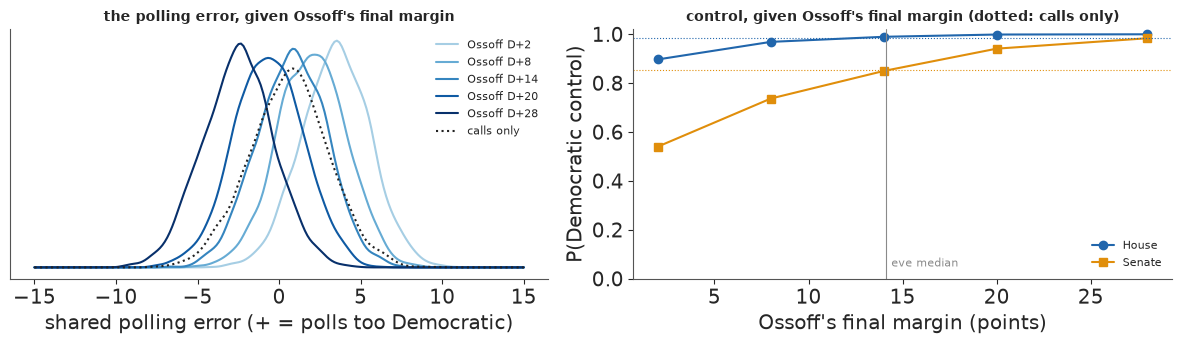

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
for y, c in zip(GA_FINAL, plt.cm.Blues(np.linspace(0.35, 1, len(GA_FINAL)))):
    ax.plot(gx, gaussian_kde(sweep[y]["bias"])(gx), color=c, label=f"Ossoff D+{y:.0f}")
ax.plot(gx, gaussian_kde(S_CALLS["bias"])(gx), color=INK, ls=":", label="calls only")
ax.set_xlabel("shared polling error (+ = polls too Democratic)")
ax.set_yticks([])
ax.legend(fontsize=8)
ax.set_title("the polling error, given Ossoff's final margin", fontsize=10)
ax = axes[1]
ax.plot(GA_FINAL, [sweep[y]["P(House)"] for y in GA_FINAL], "o-", color=D_C, label="House")
ax.plot(GA_FINAL, [sweep[y]["P(Senate)"] for y in GA_FINAL], "s-", color=GOLD, label="Senate")
ax.axhline(S_CALLS["P(House)"], color=D_C, ls=":", lw=0.8)
ax.axhline(S_CALLS["P(Senate)"], color=GOLD, ls=":", lw=0.8)
ax.axvline(fz.loc["GA-S", "pred"], color=MUTED, lw=0.8)
ax.text(fz.loc["GA-S", "pred"] + 0.3, 0.05, "eve median", color=MUTED, fontsize=8)
ax.set_xlabel("Ossoff's final margin (points)")
ax.set_ylabel("P(Democratic control)")
ax.set_ylim(0, 1.02)
ax.legend(fontsize=8, loc="lower right")
ax.set_title("control, given Ossoff's final margin (dotted: calls only)", fontsize=10)
fig.tight_layout();

The polling-error curves slide left as Ossoff's margin grows: the larger his margin, the more the polls
understated the Democrats. The control curves on the right rise with it. The Senate curve is the steeper
of the two, because Senate control hangs on a few races in Republican-leaning states that move with the
shared error, while the Democrats' House majority already had room to spare.

## 5 · What is still out

For every race still in doubt we can ask the question a viewer asks next: if the Democrat wins this one,
what happens to control, and if the Republican does? With one simulated election per draw these are
conditional frequencies: among the draws in which the Democrat wins race $r$, the share in which the
Democrats control the Senate. The difference between the two answers is how much the race matters. It
mixes two things, the seat itself and what winning it says about the polling error, which is why a race
can matter even when its seat is not the one that decides control.

In [11]:
called = {r for r, *_ in INFO if r not in closes}
open_ = [i for i in range(len(tm)) if tm.race[i] not in called and 0.05 < S0["pD"][i] < 0.95]


def cond(S, i, need, chamber):
    dwin = S["won"][:, i]
    hit = S[chamber] >= need
    return S["w"][dwin] @ hit[dwin] / S["w"][dwin].sum(), S["w"][~dwin] @ hit[~dwin] / S["w"][~dwin].sum()


rows = []
for i in open_:
    hD, hR = cond(S0, i, 218, "H")
    sD, sR = cond(S0, i, 51, "S")
    rows.append({"race": tm.race[i], "office": tm.office[i], "P(D)": S0["pD"][i], "House if D": hD,
                 "House if R": hR, "Senate if D": sD, "Senate if R": sR})
watch = pd.DataFrame(rows)
watch["House swing"] = watch["House if D"] - watch["House if R"]
watch["Senate swing"] = watch["Senate if D"] - watch["Senate if R"]
print(f"{len(watch)} races still uncertain (0.05 < P(D) < 0.95). Senate races:")
print(watch[watch.office == "S"].sort_values("Senate swing", ascending=False).round(3).to_string(index=False))
print("the House races that move House control most:")
print(watch[watch.office == "H"].sort_values("House swing", ascending=False).head(12).round(3).to_string(index=False))

95 races still uncertain (0.05 < P(D) < 0.95). Senate races:
race office  P(D)  House if D  House if R  Senate if D  Senate if R  House swing  Senate swing
MI-S      S 0.921       0.991       0.918        0.889        0.447        0.073         0.442
ME-S      S 0.909       0.989       0.945        0.893        0.453        0.045         0.440
OH-S      S 0.706       0.993       0.967        0.948        0.625        0.026         0.323
TX-S      S 0.802       0.992       0.958        0.916        0.601        0.034         0.314
IA-S      S 0.585       0.997       0.969        0.957        0.707        0.027         0.250
SC-S      S 0.457       0.998       0.975        0.975        0.751        0.023         0.223
AK-S      S 0.465       0.995       0.977        0.961        0.761        0.017         0.200
KS-S      S 0.364       0.995       0.979        0.972        0.784        0.016         0.187
NE-S      S 0.146       1.000       0.983        0.991        0.830        0.017    

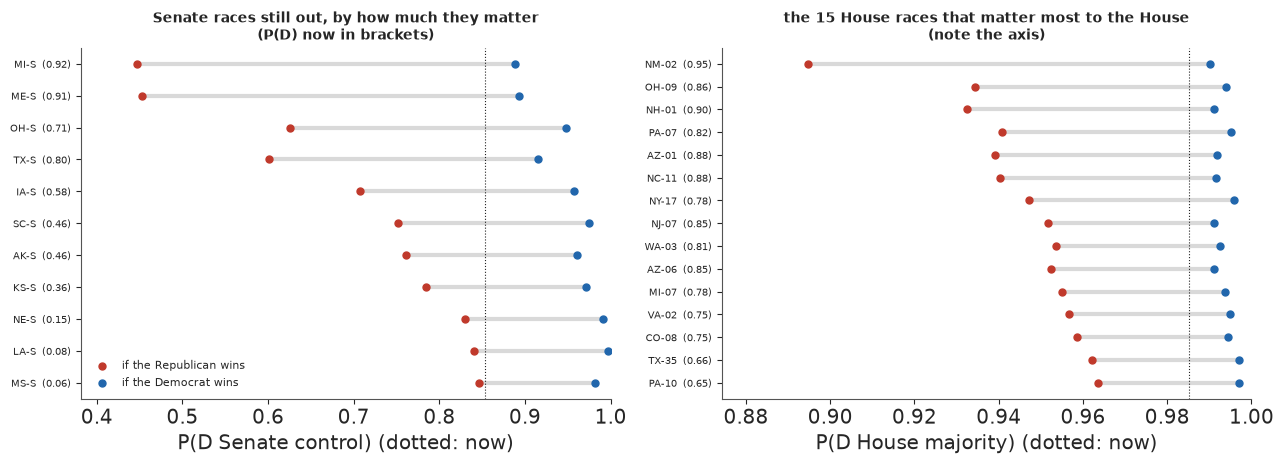

In [12]:
ws = watch[watch.office == "S"].sort_values("Senate swing")
wh = watch[watch.office == "H"].sort_values("House swing").tail(15)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, w_, a, b, lab, base in ((axes[0], ws, "Senate if R", "Senate if D", "P(D Senate control)", S0["P(Senate)"]),
                                (axes[1], wh, "House if R", "House if D", "P(D House majority)", S0["P(House)"])):
    y_ = np.arange(len(w_))
    ax.hlines(y_, w_[a], w_[b], color=LIGHT, lw=3)
    ax.scatter(w_[a], y_, color=R_C, s=25, label="if the Republican wins", zorder=3)
    ax.scatter(w_[b], y_, color=D_C, s=25, label="if the Democrat wins", zorder=3)
    ax.axvline(base, color=INK, lw=0.8, ls=":")
    ax.set_yticks(y_, [f"{r}  ({p:.2f})" for r, p in zip(w_.race, w_["P(D)"])], fontsize=7)
    ax.set_xlabel(lab + " (dotted: now)")
    lo_ = float(min(w_[a].min(), base))
    ax.set_xlim(max(0.0, lo_ - 0.1 * (1 - lo_) - 0.01), 1.0)
axes[0].legend(fontsize=8, loc="lower left")
axes[0].set_title("Senate races still out, by how much they matter\n(P(D) now in brackets)", fontsize=10)
axes[1].set_title("the 15 House races that matter most to the House\n(note the axis)", fontsize=10)
fig.tight_layout();

Two patterns hold whatever the snapshot. A race matters most when it is likely to go one way and its
loss would be a surprise: a Democratic loss in a race the Democrats were expected to win removes a seat
they were counting on and says the polls were off. So the Senate races at the top of the left panel are
often not the closest ones, but the likely Democratic wins that the Senate majority counts on. On the right, no single House race moves House control by much, because the
majority is a sum of hundreds of races; the races at the top are likely Democratic seats whose loss
would signal a broader miss. Watch the axis: it starts well above zero.

### 5.1 The map

The left map colours each state by its Senate race's chance after the night's results, with the
called states marked (D, R) and the too-close ones marked "?". The right map is the counterfactual of
section 3, now by refit: the change in every Senate race's chance had Georgia gone to Collins, with
everything else the night has shown held fixed. It shows how a single surprise would have spread: through
the shared polling error and the national margin to the Republican-leaning races, and through the
state effect to Georgia's own House seats. As in E94, there is no district map, and the counties are drawn only
to build the states.

had Georgia gone to Collins (refit): P(D Senate) 0.26 instead of 0.85, P(D House) 0.84 instead of 0.99
 race   now  had GA gone R  change
TX-35 0.663          0.366  -0.296
 OH-S 0.706          0.423  -0.283
PA-10 0.651          0.369  -0.281
TX-15 0.606          0.325  -0.281
KY-06 0.606          0.329  -0.277
PA-08 0.595          0.324  -0.271
 IA-S 0.585          0.314  -0.270
ME-02 0.537          0.270  -0.266
PA-01 0.610          0.344  -0.266
WI-01 0.500          0.236  -0.265


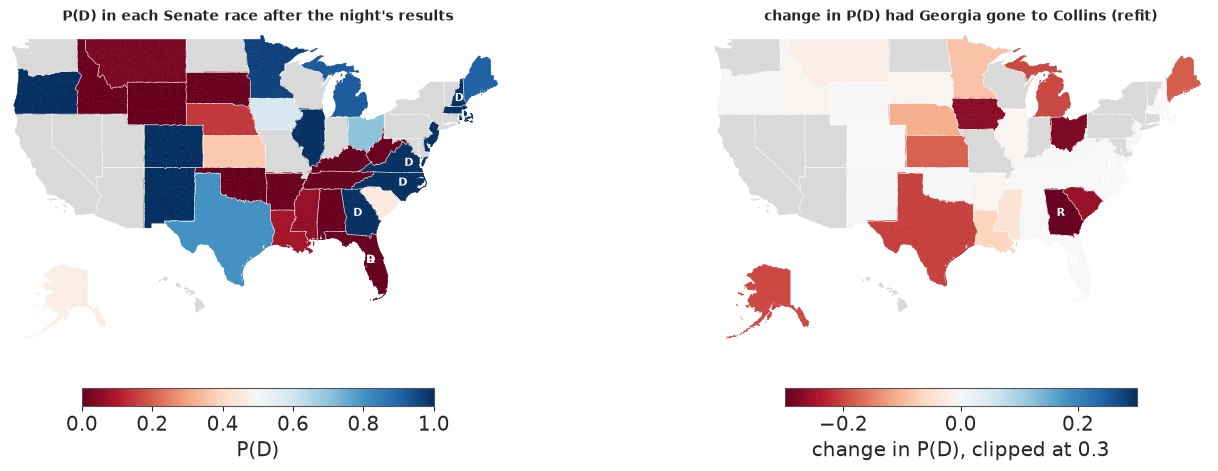

In [13]:
FIPS = {"01": "AL", "02": "AK", "04": "AZ", "05": "AR", "06": "CA", "08": "CO", "09": "CT", "10": "DE",
        "11": "DC", "12": "FL", "13": "GA", "15": "HI", "16": "ID", "17": "IL", "18": "IN", "19": "IA",
        "20": "KS", "21": "KY", "22": "LA", "23": "ME", "24": "MD", "25": "MA", "26": "MI", "27": "MN",
        "28": "MS", "29": "MO", "30": "MT", "31": "NE", "32": "NV", "33": "NH", "34": "NJ", "35": "NM",
        "36": "NY", "37": "NC", "38": "ND", "39": "OH", "40": "OK", "41": "OR", "42": "PA", "44": "RI",
        "45": "SC", "46": "SD", "47": "TN", "48": "TX", "49": "UT", "50": "VT", "51": "VA", "53": "WA",
        "54": "WV", "55": "WI", "56": "WY"}


def place(ring, st):
    """Lower 48 as longitude and latitude; Alaska and Hawaii moved and scaled into the corner (as in E94)."""
    x, y = ring[:, 0], ring[:, 1]
    if st == "AK":
        x, y = -118 + (x + 152) * 0.2, 25 + (y - 63) * 0.35
    elif st == "HI":
        x, y = -104 + (x + 157), 25 + (y - 20.5)
    return np.c_[x, y]


rings, ring_state = [], []
for ft in json.load(open(data.path("us_counties_geojson")))["features"]:
    st = FIPS.get(ft["properties"]["STATE"])
    geom = ft["geometry"]
    for poly in ([geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]):
        ring = np.asarray(poly[0], float)
        if st and not (st == "AK" and ring[:, 0].max() > 0):      # Aleutians past 180 degrees dropped
            rings.append(place(ring, st))
            ring_state.append(st)
ring_state = np.array(ring_state)
seen_ = {}
for ring, st in zip(rings, ring_state):                          # state borders, no GIS dissolve (E89)
    r_ = np.round(ring, 3)
    for a_, b_ in zip(map(tuple, r_[:-1]), map(tuple, r_[1:])):
        seen_.setdefault((a_, b_) if a_ < b_ else (b_, a_), set()).add(st)
borders = [e for e, g_ in seen_.items() if len(g_) > 1]
sen_of = {tm.state[i]: i for i in sen_rows}
ring_race = np.array([sen_of.get(s, -1) for s in ring_state])
centre = {s: np.median(np.vstack([r for r, s_ in zip(rings, ring_state) if s_ == s]), 0) for s in sen_of}

t0 = time.time()
INFO_GAR = [r for r in INFO if r[0] != "GA-S"] + GA_R
S_GAR_NUTS = summarise(eve_draws(d, night_fit(d, INFO_GAR, [m_ for m_ in MARG if m_[0] != "GA-S"])), INFO_GAR)
TIMES["counterfactual refit"] = time.time() - t0
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
cmap = plt.get_cmap("RdBu").copy()
cmap.set_bad(LIGHT)
panels = ((axes[0], S0["pD"], plt.Normalize(0, 1), INFO, "P(D) in each Senate race after the night's results", "P(D)"),
          (axes[1], S_GAR_NUTS["pD"] - S0["pD"], plt.Normalize(-0.3, 0.3), INFO_GAR,
           "change in P(D) had Georgia gone to Collins (refit)", "change in P(D), clipped at 0.3"))
for ax, v, nrm, inf_, title, lab in panels:
    vals = np.ma.masked_array(np.where(ring_race >= 0, v[np.maximum(ring_race, 0)], 0.0), ring_race < 0)
    ax.add_collection(PolyCollection(rings, array=vals, cmap=cmap, norm=nrm, edgecolor="face", linewidth=0.4))
    ax.add_collection(LineCollection(borders, color="white", lw=0.5))
    for race, lo, hi in inf_:
        mark = "D" if np.isinf(hi) else ("R" if np.isinf(lo) else "?")
        ax.text(*centre[tm.state[RACE[race]]], mark, ha="center", va="center", fontsize=8, weight="bold",
                color=INK if mark == "?" else "white")
    ax.set_xlim(-125, -66)
    ax.set_ylim(17, 50)
    ax.set_aspect(1 / np.cos(np.radians(38)))
    ax.set_axis_off()
    ax.set_title(title, fontsize=10)
    fig.colorbar(plt.cm.ScalarMappable(nrm, cmap), ax=ax, orientation="horizontal", fraction=0.05, pad=0.02, label=lab)
big = pd.DataFrame({"race": tm.race, "now": S0["pD"], "had GA gone R": S_GAR_NUTS["pD"]})
big["change"] = big["had GA gone R"] - big.now
print(f"had Georgia gone to Collins (refit): P(D Senate) {S_GAR_NUTS['P(Senate)']:.2f} instead of "
      f"{S0['P(Senate)']:.2f}, P(D House) {S_GAR_NUTS['P(House)']:.2f} instead of {S0['P(House)']:.2f}")
print(big[big.race != "GA-S"].reindex(big.change.abs().sort_values(ascending=False).index).dropna()
      .head(10).round(3).to_string(index=False))

The refit keeps the night's other results, so it does not answer quite the question of section 3's
rough reweighted row (ESS 16), but it points the same way. The House races in the list move as much as
the Senate ones: a Georgia upset would have been evidence of a Republican environment, and every seat
near the line feels that.

## 6 · Where the night stands

The bulletin below is written by the code from the latest snapshot, so it is current whenever the
notebook is rebuilt.

In [14]:
def iv(v, f, w=None):
    q_ = wq(v, w) if w is not None else np.quantile(v, [0.05, 0.5, 0.95])
    return f"{q_[1]:{f}} ({q_[0]:{f}} to {q_[2]:{f}})"


ncall = int((calls.status == "called").sum())
moved = cmp.assign(now=S0["pD"]).assign(ch=lambda x: x.now - x.eve)
moved = moved[~moved.race.isin(called)].reindex(moved.ch.abs().sort_values(ascending=False).index).dropna().head(5)
surpr = calls[calls.status == "called"].sort_values("surprise", ascending=False).head(3)
top_s = watch[watch.office == "S"].sort_values("Senate swing", ascending=False).head(3)
text = f"""**As of {AS_OF} ET**: {ncall} races called ({", ".join(calls[calls.status == "called"].race)}),
{len(closes)} too close to call ({", ".join(closes) or "none"}){"" if not MARG else
f", and {len(MARG)} counted to at least {FINAL}% ({', '.join(r for r, *_ in MARG)})"}.

* **House:** P(Democratic majority) {S0['P(House)']:.2f} (eve {EVE['P(House)']:.2f}); Democratic seats
  {iv(S0['H'], '.0f')}.
* **Senate:** P(Democratic control) {S0['P(Senate)']:.2f} (eve {EVE['P(Senate)']:.2f}); Democratic-caucus seats
  {iv(S0['S'], '.0f')}.
* **The polls:** shared polling error {iv(S0['bias'], '+.1f')} points (eve {iv(EVE['bias'], '+.1f')}); national
  House margin {iv(S0['N'], '+.1f')} (eve {iv(EVE['N'], '+.1f')}).
* **Most surprising calls:** {"; ".join(f"{r.race} for the {'Democrat' if r.winner == 'D' else 'Republican'} "
  f"(eve chance {r.pD if r.winner == 'D' else 1 - r.pD:.3f})" for r in surpr.itertuples())}.
* **Races still out that moved most:** {"; ".join(f"{r.race} {r.eve:.2f} to {r.now:.2f}" for r in moved.itertuples())}.
* **Senate races to watch:** {"; ".join(f"{r.race} (P(D) {r._3:.2f}; control {r._6:.2f} if D, {r._7:.2f} if R)"
  for r in top_s.itertuples())}.
* Reweighting and refit agree to {np.abs(cmp.reweighted - cmp.refit).max():.3f} in the race chances
  (reweighting ESS {S_RW['ess']:.0f} of {len(S_RW['w'])}).
"""
display(Markdown(text))
TIMES["total"] = time.time() - T_START
print({k: round(v) for k, v in TIMES.items()})

**As of 2026-11-03 20:50 ET**: 9 races called (GA-S, VA-S, NH-S, MA-S, RI-S, FL-S, NC-S, FL-14, FL-25),
0 too close to call (none).

* **House:** P(Democratic majority) 0.99 (eve 0.95); Democratic seats
  239 (222 to 261).
* **Senate:** P(Democratic control) 0.85 (eve 0.80); Democratic-caucus seats
  53 (49 to 56).
* **The polls:** shared polling error +0.6 (-3.5 to +4.5) points (eve +1.0 (-3.7 to +5.8)); national
  House margin +8.4 (+4.4 to +12.5) (eve +8.0 (+3.2 to +12.8)).
* **Most surprising calls:** FL-25 for the Democrat (eve chance 0.791); FL-14 for the Democrat (eve chance 0.824); FL-S for the Republican (eve chance 0.863).
* **Races still out that moved most:** CO-08 0.69 to 0.75; NC-11 0.83 to 0.88; WI-01 0.45 to 0.50; TX-23 0.26 to 0.31; ME-02 0.49 to 0.54.
* **Senate races to watch:** MI-S (P(D) 0.92; control 0.89 if D, 0.45 if R); ME-S (P(D) 0.91; control 0.89 if D, 0.45 if R); OH-S (P(D) 0.71; control 0.95 if D, 0.63 if R).
* Reweighting and refit agree to 0.033 in the race chances
  (reweighting ESS 2410 of 4000).


{'eve fit': 25, 'night refits': 26, 'margin refits': 198, 'counterfactual refit': 26, 'total': 283}


## Summary

* **An expected call says almost nothing.** Georgia's Senate race was called for Ossoff within
  minutes; the frozen forecast had given him a 0.994 chance, so the call carried 0.007 nats and moved
  the chance of a Democratic House from 0.946 to 0.948 and of a Democratic Senate from 0.801 to 0.804.
  A Collins win, at 0.0065, would have moved both chambers toward the Republicans by tens of points.
* **A call is an interval on the margin.** With the race's own noise integrated out, its likelihood is
  a normal CDF of the race's mean margin, and "too close to call" is an interval around zero. The
  reading of "too close" is an assumption, and it can be the night's largest effect, so it is shown
  with and without.
* **Reweighting is exact but fragile.** Weighting the frozen draws by the likelihood of the calls matched
  a NUTS refit with a `Potential` to a few thousandths per race on average while the ESS stayed in the hundreds or
  more. A surprising result (ESS 16 for a Collins win) or a margin known to a point (ESS in single or
  double figures) needs the refit, which takes half a minute.
* **The margin is the message.** Ossoff's final margin, unknown on the night, moves the inferred polling
  error by several points over its plausible range, and the chance of Senate control more than any
  call so far. Partial counts are not used: the early count is skewed toward the votes reported first.
* **Conditional forecasts tell you what to watch.** For each race still out, the chance of control if
  either side wins it measures how much it matters, through the seat and through what it says about the
  polls. Senate control hangs most on the likely Democratic wins that the majority counts on; no single
  House race moves House control by much.

## Try it yourself

1. **Call times as data.** A race called the moment its polls close is not close, and one called at 2
   am is. Record the minutes between poll closing and the call, model the call time as a function of the
   true margin (for example, called at closing when $|m_r|$ exceeds a threshold with a logistic edge), and
   use it in place of the bare call. How much more do the early calls say?
2. **Partial counts with a skew.** Model a partial count as the final margin plus a reporting shift that
   depends on which ballots are counted first, with a state-specific shift learned from 2018 and 2022
   county returns by reporting time. When does the partial count of Georgia become more informative than
   the call?
3. **Score the night.** Once every race is called, compare the log scores of the frozen forecast and of
   this notebook's forecast at each hour of the night on the races still out at that hour. Did updating on
   the calls improve the forecasts of the races that came in later?